# Klasifikasi Test Results dengan KNN — Healthcare Dataset


## Tahap 1 — Perumusan masalah

**Skenario prediksi:** memperkirakan *Test Results* (Normal / Abnormal / Inconclusive) **saat pasien baru masuk**, sebelum tes dilakukan. Dataset tidak memiliki dokumentasi kapan setiap kolom dicatat, sehingga skenario ini adalah asumsi penelitian.

**Label kolom:** M = tersedia saat masuk, P = baru ada setelah perawatan, I = identitas (tidak bermakna sebagai fitur).

| Kolom | Label | Kolom | Label |
|---|---|---|---|
| Name | I | Insurance Provider | M |
| Age | M | Billing Amount | P |
| Gender | M | Room Number | I |
| Blood Type | M | Admission Type | M |
| Medical Condition | M (asumsi) | Discharge Date | P |
| Date of Admission | M | Medication | P (ambigu) |
| Doctor | I | Hospital | I |

**Rencana analisis**
- Fitur utama: Age, Gender, Blood Type, Medical Condition, Insurance Provider, Admission Type. Analisis sensitivitas: + Medication.
- Metrik utama: akurasi + F1 macro. Pendukung: precision, recall, F1 per kelas, confusion matrix.
- Baseline: `DummyClassifier` most_frequent dan stratified.
- Split: hold-out test 10% stratified, seed 42, setelah data cleaning.
- CV: 5-fold stratified untuk tuning, diulang 2–3 kali untuk perbandingan akhir.
- Uji sinyal: permutation test (100 permutasi, hiperparameter tetap) untuk KNN dan XGBoost.
- Perbandingan model: berpasangan per fold, rata-rata ± std, uji Wilcoxon.

## Tahap 2 — Pengumpulan dan pemahaman data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats.contingency import association
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import pairwise_distances
from xgboost import XGBClassifier
import time
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, permutation_test_score, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
TARGET = "Test Results"

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("healthcare_dataset.csv")
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [3]:
print("Ukuran data:", df.shape)
print("Nilai kosong total:", df.isna().sum().sum())

Ukuran data: (55500, 15)
Nilai kosong total: 0


**Interpretasi:** Dataset terdiri dari 55.500 baris dan 15 kolom, tanpa nilai kosong sama sekali. Tidak diperlukan imputasi, tetapi kelengkapan yang sempurna seperti ini juga merupakan ciri umum data sintetis.

In [4]:
df.dtypes

Name                   object
Age                     int64
Gender                 object
Blood Type             object
Medical Condition      object
Date of Admission      object
Doctor                 object
Hospital               object
Insurance Provider     object
Billing Amount        float64
Room Number             int64
Admission Type         object
Discharge Date         object
Medication             object
Test Results           object
dtype: object

**Interpretasi:** Kolom `Date of Admission` dan `Discharge Date` masih terbaca sebagai teks, sehingga perlu dikonversi ke tipe tanggal sebelum bisa dihitung selisihnya.

In [5]:
df.nunique()

Name                  49992
Age                      77
Gender                    2
Blood Type                8
Medical Condition         6
Date of Admission      1827
Doctor                40341
Hospital              39876
Insurance Provider        5
Billing Amount        50000
Room Number             400
Admission Type            3
Discharge Date         1856
Medication                5
Test Results              3
dtype: int64

**Interpretasi:** Name, Doctor, dan Hospital memiliki sekitar 40–50 ribu nilai unik, hampir satu nilai per pasien, sehingga tidak bermakna sebagai fitur (label I). Billing Amount memiliki tepat 50.000 nilai unik dari 55.500 baris, padahal kolom kontinu seperti tagihan seharusnya hampir selalu unik. Ini petunjuk awal adanya baris salinan yang diselidiki pada Tahap 3.

## Tahap 3 — Data cleaning (seluruh data, sebelum split)

### 3.1 Konversi kolom tanggal dan lama rawat inap

In [6]:
kolom_tanggal = ["Date of Admission", "Discharge Date"]

for c in kolom_tanggal:
    df[c] = pd.to_datetime(df[c], format="%Y-%m-%d")

df[kolom_tanggal].dtypes

Date of Admission    datetime64[ns]
Discharge Date       datetime64[ns]
dtype: object

In [7]:
df["los_days"] = (df["Discharge Date"] - df["Date of Admission"]).dt.days
print("Rentang los_days:", df["los_days"].min(), "-", df["los_days"].max())

Rentang los_days: 1 - 30


**Interpretasi:** Kedua kolom tanggal kini bertipe `datetime64`. Lama rawat inap berkisar 1–30 hari tanpa nilai negatif atau nol, sehingga tidak ada tanggal pulang yang mendahului tanggal masuk.

### 3.2 Konsistensi kolom Name

In [8]:
df["name_clean"] = df["Name"].str.lower().str.strip()

print("Contoh nama asli:", df["Name"].head(3).tolist())
print("Nama unik asli         :", df["Name"].nunique())
print("Nama unik (lowercase)  :", df["name_clean"].nunique())

Contoh nama asli: ['Bobby JacksOn', 'LesLie TErRy', 'DaNnY sMitH']
Nama unik asli         : 49992
Nama unik (lowercase)  : 40235


**Interpretasi:** Penulisan huruf besar-kecil pada Name tidak konsisten. Setelah dirapikan, jumlah nama unik turun dari 49.992 menjadi 40.235.

Apakah nama yang sama menunjukkan pasien yang sama? Kita uji dengan membandingkan Gender dan Blood Type, dua atribut yang tidak mungkin berubah untuk satu orang.

In [9]:
cek = df.groupby("name_clean").agg(
    n_baris=("Age", "size"),
    gender_unik=("Gender", "nunique"),
    blood_unik=("Blood Type", "nunique"),
)
cek_multi = cek[cek["n_baris"] > 1]

print("Nama yang muncul >1 kali   :", len(cek_multi))
print("Proporsi Gender berbeda    :", round((cek_multi["gender_unik"] > 1).mean(), 3))
print("Proporsi Blood Type berbeda:", round((cek_multi["blood_unik"] > 1).mean(), 3))

Nama yang muncul >1 kali   : 9740
Proporsi Gender berbeda    : 0.356
Proporsi Blood Type berbeda: 0.559


**Interpretasi:** Dari 9.740 nama yang muncul lebih dari sekali, 35,6% memiliki Gender berbeda dan 55,9% memiliki Blood Type berbeda. Nama yang sama sebagian besar adalah orang yang berbeda. Dataset tidak memiliki ID pasien yang andal, sehingga validasi berbasis kelompok pasien (`GroupKFold`) tidak diterapkan.

### 3.3 Duplikat persis

In [10]:
kolom_asli = [c for c in df.columns if c not in ["name_clean", "los_days"]]

print("Baris duplikat (ditandai)    :", df.duplicated(subset=kolom_asli).sum())
print("Baris yang terlibat duplikasi:", df.duplicated(subset=kolom_asli, keep=False).sum())

Baris duplikat (ditandai)    : 534
Baris yang terlibat duplikasi: 1068


**Interpretasi:** Terdapat 534 pasang baris yang identik di semua kolom (1.068 baris terlibat). Jika satu baris berada di train dan kembarannya di test, KNN akan menemukan kembarannya di jarak 0 dan skor evaluasi menjadi terlalu optimis.

In [11]:
df = df.drop_duplicates(subset=kolom_asli, keep="first").reset_index(drop=True)
print("Ukuran setelah buang duplikat persis:", df.shape)

Ukuran setelah buang duplikat persis: (54966, 17)


### 3.4 Near-duplicate
Baris yang identik di semua kolom **kecuali Age**.

In [12]:
kunci_near = [c for c in kolom_asli if c != "Age"]
near = df.duplicated(subset=kunci_near, keep=False)

print("Baris terlibat near-duplicate:", near.sum())
print("Jumlah kelompok              :", df.loc[near, "Billing Amount"].nunique())

Baris terlibat near-duplicate: 9932
Jumlah kelompok              : 4966


**Interpretasi:** Ditemukan 9.932 baris (4.966 pasang) yang identik di semua kolom kecuali Age.

Berapa selisih umur di setiap pasangan near-duplicate, dan apakah labelnya selalu sama?

In [13]:
kelompok_near = df[near].groupby("Billing Amount")

selisih_age = kelompok_near["Age"].agg(lambda a: a.max() - a.min())
selisih_age.describe().round(2)

count    4966.00
mean        2.74
std         1.32
min         1.00
25%         2.00
50%         3.00
75%         4.00
max         5.00
Name: Age, dtype: float64

In [14]:
label_selalu_sama = (kelompok_near[TARGET].nunique() == 1).all()
print("Label dalam setiap kelompok selalu sama?:", label_selalu_sama)

print("Rentang Age pada baris NON near-duplicate:",
      df.loc[~near, "Age"].min(), "-", df.loc[~near, "Age"].max())
print("Baris near-duplicate dengan Age di luar 18-85:",
      ((df.loc[near, "Age"] < 18) | (df.loc[near, "Age"] > 85)).sum())

Label dalam setiap kelompok selalu sama?: True
Rentang Age pada baris NON near-duplicate: 18 - 85
Baris near-duplicate dengan Age di luar 18-85: 221


**Interpretasi:** Selisih umur dalam setiap pasangan hanya 1–5 tahun (median 3), dan label Test Results selalu sama. Semua umur di luar rentang 18–85 tahun (221 baris) hanya muncul pada baris near-duplicate, sehingga baris-baris ini tampaknya adalah salinan dengan umur yang digeser. Ini lebih berbahaya daripada duplikat persis: dengan fitur model kita, kembarannya hanya berbeda di Age, sehingga KNN akan menganggapnya tetangga terdekat dan "mencontek" labelnya.

In [15]:
df = df.drop_duplicates(subset=kunci_near, keep="first").reset_index(drop=True)
print("Ukuran setelah buang near-duplicate:", df.shape)

Ukuran setelah buang near-duplicate: (50000, 17)


**Interpretasi:** Setelah near-duplicate dibuang, data tersisa tepat 50.000 baris. Kami menduga dataset ini terdiri dari 50.000 rekaman asli ditambah 5.500 salinan (534 salinan persis dan 4.966 salinan dengan umur yang digeser). Dugaan ini didukung tiga bukti: total baris yang dibuang tepat 5.500, kolom Billing Amount pada data mentah memiliki tepat 50.000 nilai unik, dan semua umur di luar rentang 18–85 tahun hanya muncul pada baris salinan. Karena tidak ada dokumentasi dari pembuat dataset, dugaan ini tidak dapat dikonfirmasi secara langsung.

## Tahap 4 — Split data

In [16]:
train, test = train_test_split(
    df, test_size=0.10, stratify=df[TARGET], random_state=SEED
)
print("Train:", train.shape, "| Test:", test.shape)

Train: (45000, 17) | Test: (5000, 17)


In [17]:
pd.DataFrame({
    "train": train[TARGET].value_counts(normalize=True),
    "test": test[TARGET].value_counts(normalize=True),
}).round(4)

,train,test
Test Results,,
Abnormal,0.3354,0.3354
Normal,0.3337,0.3338
Inconclusive,0.3309,0.3308


**Interpretasi:** Data dibagi menjadi 45.000 baris latih dan 5.000 baris uji secara stratified, sehingga proporsi kelas di keduanya hampir sama. Ketiga kelas hampir seimbang (sekitar 33% masing-masing), sehingga baseline most-frequent berada di sekitar 33,5%. Dengan sekitar 1.650 sampel per kelas di test set, satu kesalahan prediksi hanya menggeser recall satu kelas sekitar 0,06 poin persen.

### 4.1 Verifikasi: tidak ada kebocoran lintas split

In [18]:
overlap = pd.merge(train[kunci_near], test[kunci_near], how="inner", on=kunci_near)
print("Near-duplicate yang tersisa lintas train-test:", len(overlap))

Near-duplicate yang tersisa lintas train-test: 0


**Interpretasi:** Tidak ada baris di test set yang identik dengan baris di train set (dengan mengabaikan Age). Pembersihan pada Tahap 3 berhasil mencegah kebocoran melalui baris salinan.

## Tahap 5 — Exploratory Data Analysis (data latih)

In [19]:
cat_cols = ["Gender", "Blood Type", "Medical Condition",
            "Insurance Provider", "Admission Type", "Medication"]
num_cols = ["Age", "Billing Amount", "los_days"]

### 5.1 Distribusi fitur numerik

In [20]:
train[num_cols].describe().round(2)

,Age,Billing Amount,los_days
count,45000.00,45000.00,45000.00
mean,51.59,25559.52,15.49
std,19.56,14222.86,8.65
min,18.00,-2008.49,1.00
25%,35.00,13229.16,8.00
50%,52.00,25556.10,15.00
75%,68.00,37876.14,23.00
max,85.00,52764.28,30.00


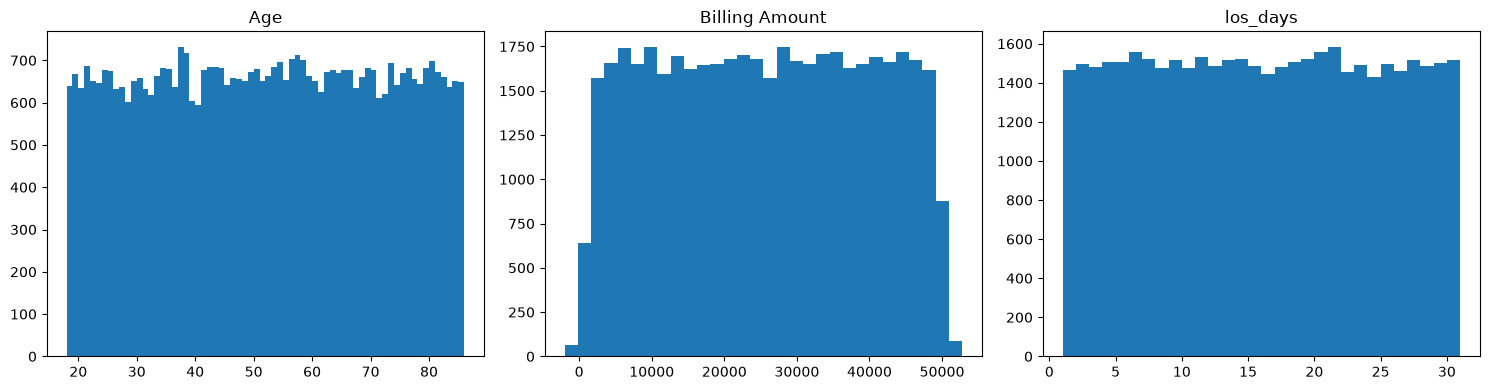

In [21]:
# Age dan los_days berupa bilangan bulat, jadi bin dibuat per nilai
# supaya batang histogram tidak naik-turun karena pembagian bin yang tidak rata
bins = {
    "Age": np.arange(train["Age"].min(), train["Age"].max() + 2),
    "Billing Amount": 30,
    "los_days": np.arange(1, 32),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    ax.hist(train[c], bins=bins[c])
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Interpretasi:** Age berkisar 18–85 tahun dengan rata-rata 51,6. Billing Amount memiliki nilai negatif (minimum −2.008), yang tidak masuk akal untuk tagihan, tetapi kolom ini berlabel P sehingga tidak dipakai sebagai fitur. Histogram Age dan `los_days` tampak datar: setiap nilai umur dan setiap lama rawat inap muncul dengan frekuensi yang hampir sama. Billing Amount juga datar di rentang sekitar 0–50.000, hanya dengan ekor tipis di kedua ujungnya (sekitar 1% data). Tidak ada puncak atau kemiringan yang biasa terlihat pada data nyata, misalnya umur pasien yang terkonsentrasi di kelompok lansia.

Pembanding untuk `los_days`: distribusi **seragam diskrit 1–30**.

In [22]:
n = 30
mean_seragam = (1 + n) / 2
std_seragam = np.sqrt((n**2 - 1) / 12)

print("Seragam 1-30 -> mean:", mean_seragam, "| std:", round(std_seragam, 3))
print("los_days train -> mean:", round(train["los_days"].mean(), 3),
      "| std:", round(train["los_days"].std(), 3))

Seragam 1-30 -> mean: 15.5 | std: 8.655
los_days train -> mean: 15.489 | std: 8.647


### 5.2 Distribusi fitur kategorikal

In [23]:
for c in cat_cols:
    print(f"\n{c}:")
    print(train[c].value_counts(normalize=True).round(3).to_string())


Gender:
Gender
Male      0.5
Female    0.5

Blood Type:
Blood Type
AB+    0.126
A-     0.126
AB-    0.125
A+     0.125
O+     0.125
B-     0.125
B+     0.124
O-     0.124

Medical Condition:
Medical Condition
Arthritis       0.168
Hypertension    0.167
Diabetes        0.167
Cancer          0.167
Obesity         0.165
Asthma          0.165

Insurance Provider:
Insurance Provider
Cigna               0.202
Medicare            0.201
UnitedHealthcare    0.200
Blue Cross          0.199
Aetna               0.197

Admission Type:
Admission Type
Elective     0.336
Urgent       0.335
Emergency    0.328

Medication:
Medication
Lipitor        0.201
Penicillin     0.201
Paracetamol    0.200
Ibuprofen      0.200
Aspirin        0.199


**Interpretasi:** Semua fitur kategorikal terdistribusi hampir rata sempurna: Gender 50/50, delapan golongan darah masing-masing sekitar 12,5%, enam kondisi medis sekitar 16,7%, lima asuransi sekitar 20%, tiga tipe masuk sekitar 33%, dan lima obat sekitar 20%. Pada data nyata, proporsi seperti ini hampir tidak pernah serata itu, misalnya golongan darah O+ biasanya jauh lebih umum daripada AB−.

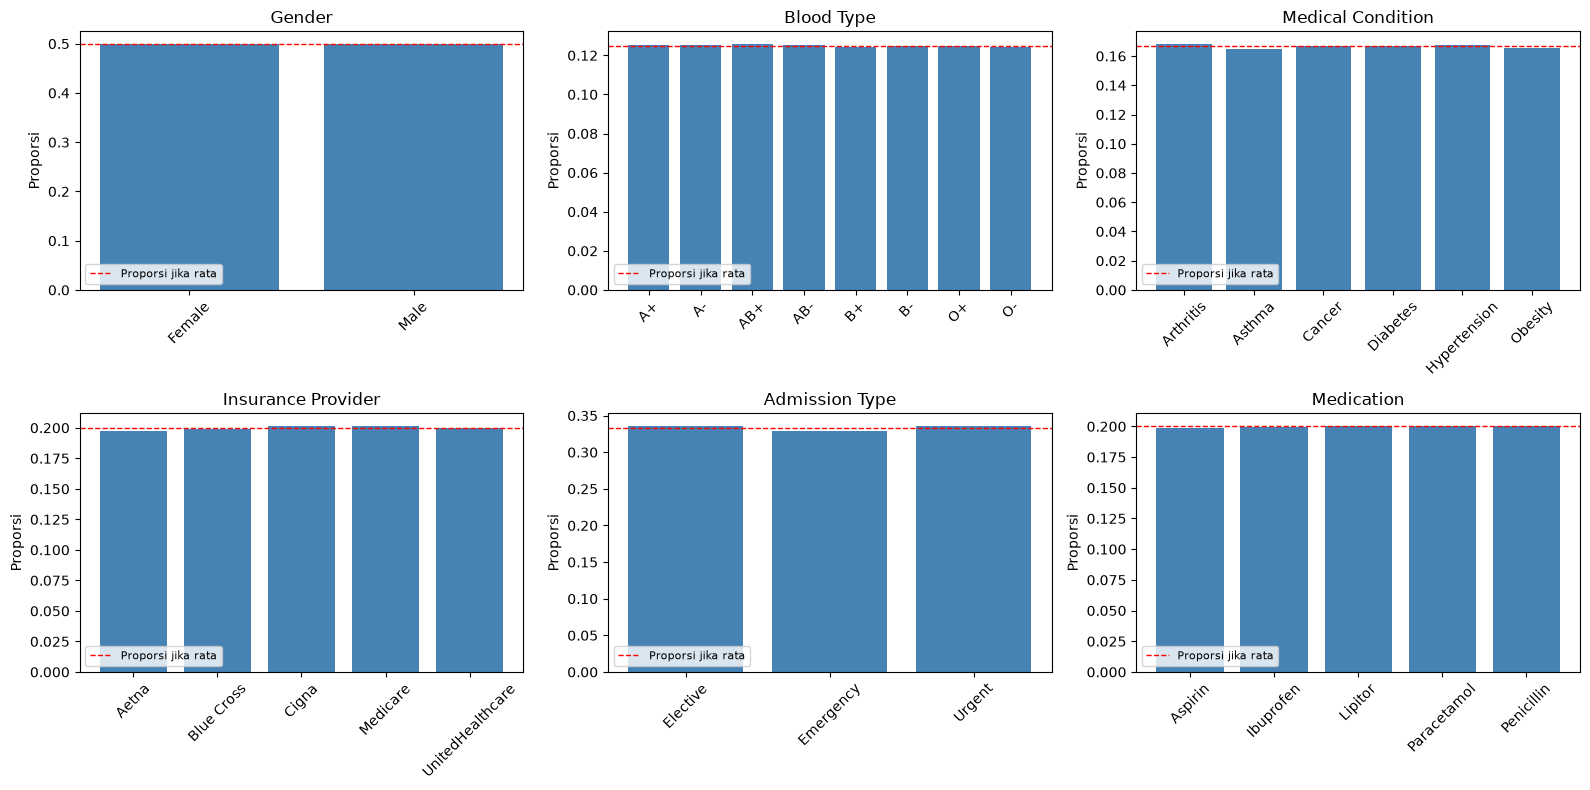

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    proporsi = train[c].value_counts(normalize=True).sort_index()
    ax.bar(proporsi.index.astype(str), proporsi.values, color="steelblue")
    ax.axhline(1 / len(proporsi), color="red", linestyle="--", linewidth=1,
               label="Proporsi jika rata")
    ax.set_title(c)
    ax.set_ylabel("Proporsi")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi:** Batang setiap kategori hampir menyentuh garis merah, yaitu proporsi yang diharapkan jika semua kategori muncul sama sering (1/jumlah kategori). Grafik ini menegaskan secara visual bahwa semua fitur kategorikal terbagi hampir rata sempurna, pola yang jarang ditemui pada data rumah sakit nyata.

### 5.3 Hubungan fitur dengan label
- Kategorikal: chi-square + Cramér's V
- Numerik: Kruskal-Wallis + epsilon²
- p-value dikoreksi Bonferroni karena ada banyak uji sekaligus

Hasil tahap ini bersifat **eksploratif** (indikasi), bukan bukti.

Sebelum uji statistik, hubungan fitur dengan label dilihat secara visual: untuk setiap kategori, berapa proporsi pasien yang hasil tesnya Abnormal, Inconclusive, dan Normal? Jika suatu fitur berhubungan dengan label, proporsi ini akan berbeda antar kategori.

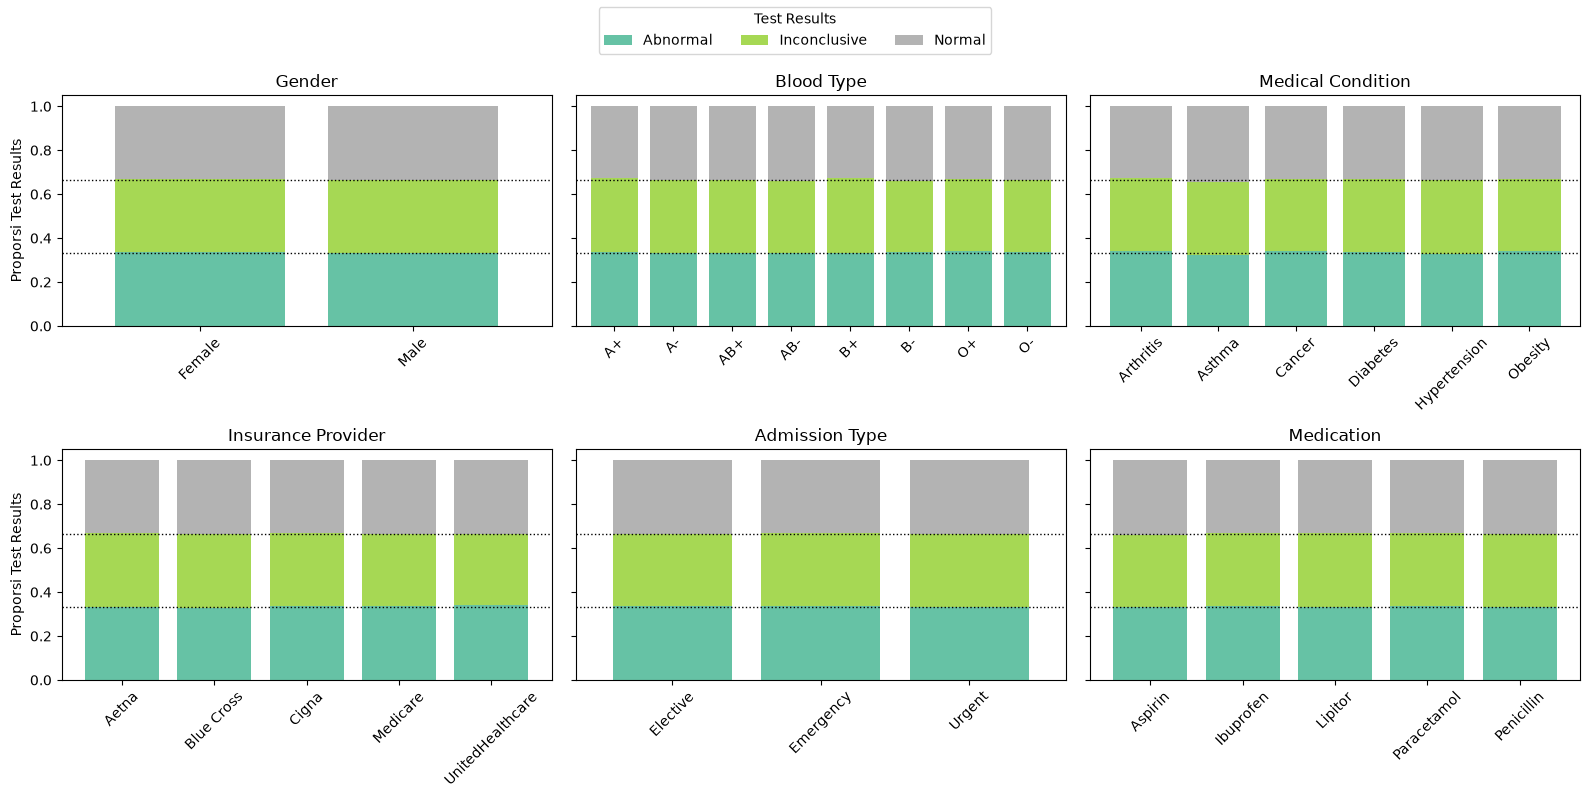

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, c in zip(axes.ravel(), cat_cols):
    tab = pd.crosstab(train[c], train[TARGET], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=ax, colormap="Set2", legend=False, width=0.8)
    for y in [1/3, 2/3]:
        ax.axhline(y, color="black", linestyle=":", linewidth=1)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("Proporsi Test Results")
    ax.tick_params(axis="x", rotation=45)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, title="Test Results")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Interpretasi:** Di semua fitur kategorikal, setiap batang terbagi hampir tepat menjadi tiga bagian yang sama, mengikuti garis putus-putus di 1/3 dan 2/3. Proporsi setiap kelas di setiap kategori hanya berkisar 0,32–0,35. Misalnya, pasien dengan kondisi Cancer memiliki proporsi Abnormal 0,342, hampir sama dengan pasien Asthma (0,325). Tidak ada kategori yang membuat suatu hasil tes lebih mungkin muncul.

In [26]:
# Age dikelompokkan supaya bisa dibandingkan dengan cara yang sama
kelompok_umur = pd.cut(train["Age"], bins=[17, 30, 45, 60, 75, 85])
pd.crosstab(kelompok_umur, train[TARGET], normalize="index").round(3)

Test Results,Abnormal,Inconclusive,Normal
Age,,,
"(17, 30]",0.331,0.325,0.345
"(30, 45]",0.334,0.331,0.335
"(45, 60]",0.336,0.334,0.330
"(60, 75]",0.338,0.334,0.328
"(75, 85]",0.339,0.329,0.331


**Interpretasi:** Pola yang sama juga terlihat pada umur. Proporsi Abnormal hanya bergeser dari 0,331 (18–30 tahun) menjadi 0,339 (76–85 tahun). Pada data medis nyata, pasien yang lebih tua umumnya lebih sering memiliki hasil tes abnormal, tetapi pola itu tidak muncul di sini.

In [27]:
rows = []
for c in cat_cols:
    tab = pd.crosstab(train[c], train[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    rows.append({"fitur": c, "uji": "chi-square", "statistik": chi2, "p": p,
                 "efek": association(tab.values, method="cramer"),
                 "ukuran_efek": "Cramer's V"})

for c in num_cols:
    groups = [g[c].values for _, g in train.groupby(TARGET)]
    h, p = stats.kruskal(*groups)
    eps2 = (h - len(groups) + 1) / (len(train) - len(groups))
    rows.append({"fitur": c, "uji": "Kruskal-Wallis", "statistik": h, "p": p,
                 "efek": eps2, "ukuran_efek": "epsilon^2"})

hasil = pd.DataFrame(rows)
hasil["p_bonferroni"] = (hasil["p"] * len(hasil)).clip(upper=1)
hasil.round(5)

,fitur,uji,statistik,p,efek,ukuran_efek,p_bonferroni
0,Gender,chi-square,0.98262,0.61182,0.00467,Cramer's V,1.00000
1,Blood Type,chi-square,7.33190,0.92116,0.00903,Cramer's V,1.00000
2,Medical Condition,chi-square,11.69310,0.30612,0.01140,Cramer's V,1.00000
3,Insurance Provider,chi-square,6.97424,0.53941,0.00880,Cramer's V,1.00000
4,Admission Type,chi-square,1.29906,0.86154,0.00380,Cramer's V,1.00000
5,Medication,chi-square,2.43654,0.96462,0.00520,Cramer's V,1.00000
6,Age,Kruskal-Wallis,4.48669,0.10610,0.00006,epsilon^2,0.95493
7,Billing Amount,Kruskal-Wallis,1.04048,0.59438,-0.00002,epsilon^2,1.00000
8,los_days,Kruskal-Wallis,1.51548,0.46872,-0.00001,epsilon^2,1.00000


**Interpretasi:** Tidak ada fitur yang berhubungan signifikan dengan Test Results. Seluruh p-value di atas 0,05 bahkan sebelum koreksi, dan setelah koreksi Bonferroni p terkecil adalah 0,95 (Age). Ukuran efeknya juga sangat kecil: Cramér's V tertinggi 0,011 (Medical Condition) dan epsilon² praktis nol untuk semua fitur numerik.

### 5.4 Mutual information
MI menangkap hubungan apa pun (tidak harus linear) antara satu fitur dan label.

In [28]:
X_mi = train[cat_cols + num_cols].copy()
for c in cat_cols:
    X_mi[c] = X_mi[c].astype("category").cat.codes

mi = mutual_info_classif(
    X_mi, train[TARGET],
    discrete_features=[True] * len(cat_cols) + [False] * len(num_cols),
    random_state=SEED,
)
pd.Series(mi, index=X_mi.columns, name="MI (nats)").sort_values(ascending=False).round(5)

Age                   0.00353
los_days              0.00115
Medical Condition     0.00013
Blood Type            0.00008
Insurance Provider    0.00008
Medication            0.00003
Admission Type        0.00001
Gender                0.00001
Billing Amount        0.00000
Name: MI (nats), dtype: float64

**Interpretasi:** Semua nilai MI mendekati nol, dengan nilai tertinggi sekitar 0,0035 nats (Age). Sebelum near-duplicate dibuang, Billing Amount sempat memiliki MI 0,041. Nilai itu hilang setelah pembersihan, menunjukkan bahwa MI tinggi tadi adalah artefak dari nilai kembar, bukan sinyal.

### 5.5 Multikolinearitas antar fitur

In [29]:
train[num_cols].corr(method="spearman").round(3)

,Age,Billing Amount,los_days
Age,1.000,-0.002,0.009
Billing Amount,-0.002,1.000,-0.005
los_days,0.009,-0.005,1.000


In [30]:
pairs = []
for i, a in enumerate(cat_cols):
    for b in cat_cols[i + 1:]:
        v = association(pd.crosstab(train[a], train[b]).values, method="cramer")
        pairs.append((a, b, round(v, 4)))

pd.DataFrame(pairs, columns=["fitur_a", "fitur_b", "cramers_v"]) \
  .sort_values("cramers_v", ascending=False).head()

,fitur_a,fitur_b,cramers_v
0,Gender,Blood Type,0.0186
3,Gender,Admission Type,0.0138
7,Blood Type,Admission Type,0.0128
10,Medical Condition,Admission Type,0.0127
12,Insurance Provider,Admission Type,0.0125


**Interpretasi:** Korelasi Spearman antar fitur numerik di bawah 0,01, dan Cramér's V antar fitur kategorikal paling tinggi 0,019 (Gender–Blood Type). Fitur-fitur ini praktis saling independen, sehingga multikolinearitas bukan masalah.

## Tahap 6 — Preprocessing
Semua transformasi yang **belajar dari data** (scaling, encoding) dibungkus di dalam `Pipeline`, sehingga di setiap fold CV transformasi hanya di-fit di data latih fold tersebut.

### 6.1 Pemilihan fitur
Sesuai Tahap 1: hanya kolom berlabel **M** yang dipakai. Medication disimpan untuk analisis sensitivitas.

In [31]:
FITUR_NUM = ["Age"]
FITUR_KAT = ["Gender", "Blood Type", "Medical Condition",
             "Insurance Provider", "Admission Type"]
FITUR = FITUR_NUM + FITUR_KAT
FITUR_SENSITIVITAS = FITUR + ["Medication"]

X_train, y_train = train[FITUR], train[TARGET]
X_test, y_test = test[FITUR], test[TARGET]
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (45000, 6) | X_test: (5000, 6)


**Interpretasi:** Fitur model terdiri dari 6 kolom (1 numerik, 5 kategorikal), dengan 45.000 baris latih dan 5.000 baris uji.

XGBoost membutuhkan label berupa angka 0, 1, 2. `LabelEncoder` di-fit di data latih saja.

In [32]:
le = LabelEncoder().fit(y_train)
y_train_enc = le.transform(y_train)
y_test_enc = le.transform(y_test)
dict(zip(le.classes_, le.transform(le.classes_)))

{'Abnormal': np.int64(0), 'Inconclusive': np.int64(1), 'Normal': np.int64(2)}

**Interpretasi:** Label diurutkan menurut abjad: Abnormal = 0, Inconclusive = 1, Normal = 2. Urutan angka ini hanya penamaan kelas, bukan urutan bermakna, dan tidak memengaruhi model karena label tidak dipakai untuk menghitung jarak.

### 6.2 Pipeline KNN
- Age → `StandardScaler` (mean 0, std 1)
- Lima fitur kategorikal → `OneHotEncoder`, karena tidak punya urutan alami. `handle_unknown="ignore"` mencegah error jika test set berisi kategori yang tidak ada di data latih.

In [33]:
prep_knn = ColumnTransformer([
    ("num", StandardScaler(), FITUR_NUM),
    ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_KAT),
])

knn_pipe = Pipeline([
    ("prep", prep_knn),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
knn_pipe

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age']),
                                                 ('kat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Gender', 'Blood Type',
                                                   'Medical Condition',
                                                   'Insurance Provider',
                                                   'Admission Type'])])),
                ('knn', KNeighborsClassifier())])

### 6.3 Pipeline XGBoost
- Tanpa scaling: pohon membagi data dengan threshold, jadi skala fitur tidak berpengaruh.
- Fitur kategorikal di-encode jadi kode angka dengan `OrdinalEncoder`, lalu XGBoost diberi tahu lewat `feature_types` bahwa kolom itu **kategorikal**, sehingga kodenya diperlakukan sebagai kategori, bukan urutan.

In [34]:
prep_xgb = ColumnTransformer([
    ("num", "passthrough", FITUR_NUM),
    ("kat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), FITUR_KAT),
])

xgb_pipe = Pipeline([
    ("prep", prep_xgb),
    ("xgb", XGBClassifier(
        tree_method="hist",
        enable_categorical=True,
        feature_types=["q"] * len(FITUR_NUM) + ["c"] * len(FITUR_KAT),
        random_state=SEED,
        n_jobs=-1,
    )),
])
xgb_pipe

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Age']),
                                                 ('kat',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=nan),
                                                  ['Gender', 'Blood Type',
                                                   'Medical Condition',
                                                   'Insurance Provider',
                                                   'Admission Type'])])),
                ('xgb',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=N...
                               feature_weights=None, gamma=None,
                               grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=-1,
                               num_parallel_tree=None, ...))])

### 6.4 Pengecekan pasca-preprocessing (data latih)
Pengecekan dilakukan dengan mem-fit bagian `prep` di data latih saja. Ini hanya untuk memeriksa hasil transformasi, bukan untuk melatih model.

#### 6.4.1 Sanity check KNN

In [35]:
Xt_knn = prep_knn.fit_transform(X_train)
nama_kolom = prep_knn.get_feature_names_out()

print("Ukuran setelah transformasi:", Xt_knn.shape)
print("Ada NaN/inf?:", not np.isfinite(Xt_knn).all())
print("Age -> mean:", round(Xt_knn[:, 0].mean(), 4), "| std:", round(Xt_knn[:, 0].std(), 4))

Ukuran setelah transformasi: (45000, 25)
Ada NaN/inf?: False
Age -> mean: 0.0 | std: 1.0


In [36]:
# Setiap fitur kategorikal asal harus menghasilkan tepat satu angka 1 per baris
for f in FITUR_KAT:
    idx = [i for i, n in enumerate(nama_kolom) if n.startswith(f"kat__{f}_")]
    jumlah = Xt_knn[:, idx].sum(axis=1)
    print(f"{f:<20} kolom: {len(idx)} | jumlah per baris selalu 1: {np.all(jumlah == 1)}")

Gender               kolom: 2 | jumlah per baris selalu 1: True
Blood Type           kolom: 8 | jumlah per baris selalu 1: True
Medical Condition    kolom: 6 | jumlah per baris selalu 1: True
Insurance Provider   kolom: 5 | jumlah per baris selalu 1: True
Admission Type       kolom: 3 | jumlah per baris selalu 1: True


**Interpretasi:** Hasil transformasi KNN berukuran 45.000 × 25 (1 kolom Age + 24 kolom one-hot), tanpa NaN atau inf. Age memiliki mean 0 dan std 1 di data latih, dan setiap fitur kategorikal menghasilkan tepat satu angka 1 per baris. Transformasi bekerja sesuai rumusnya.

#### 6.4.2 Geometri jarak KNN
Menghitung matriks jarak 45.000 × 45.000 terlalu berat, jadi dipakai sampel acak 2.000 baris dari data latih.

In [37]:
rng = np.random.default_rng(SEED)
idx_sampel = rng.choice(len(Xt_knn), size=2000, replace=False)
S = Xt_knn[idx_sampel]

# Kontribusi rata-rata setiap kelompok fitur ke jarak kuadrat antar pasangan
kontribusi = {}
D_age = pairwise_distances(S[:, [0]], metric="sqeuclidean")
kontribusi["Age"] = D_age[np.triu_indices(len(S), 1)].mean()
for f in FITUR_KAT:
    idx = [i for i, n in enumerate(nama_kolom) if n.startswith(f"kat__{f}_")]
    D = pairwise_distances(S[:, idx], metric="sqeuclidean")
    kontribusi[f] = D[np.triu_indices(len(S), 1)].mean()

kontribusi = pd.Series(kontribusi)
pd.DataFrame({"rata2_jarak_kuadrat": kontribusi.round(3),
              "porsi_%": (100 * kontribusi / kontribusi.sum()).round(1)})

,rata2_jarak_kuadrat,porsi_%
Age,1.975,21.2
Gender,1.000,10.7
Blood Type,1.748,18.8
Medical Condition,1.667,17.9
Insurance Provider,1.599,17.1
Admission Type,1.334,14.3


**Interpretasi:** Age menyumbang sekitar 21% jarak kuadrat rata-rata, sedangkan setiap fitur kategorikal menyumbang 11–19%. Angka ini sesuai teori: selisih dua nilai yang sudah distandarisasi memiliki rata-rata kuadrat 2, dan fitur one-hot dengan k kategori yang seimbang menyumbang 2(1 − 1/k), misalnya 1,75 untuk Blood Type (k = 8) dan 1 untuk Gender (k = 2). Tidak ada satu kelompok fitur pun yang menguasai jarak, sehingga kombinasi StandardScaler dan one-hot sudah seimbang.

In [38]:
# Rasio jarak tetangga terdekat vs terjauh, dan titik identik
D = pairwise_distances(S, metric="euclidean")
np.fill_diagonal(D, np.nan)
terdekat = np.nanmin(D, axis=1)
terjauh = np.nanmax(D, axis=1)

print("Median jarak terdekat:", round(np.median(terdekat), 3))
print("Median jarak terjauh :", round(np.median(terjauh), 3))
print("Median rasio terdekat/terjauh:", round(np.median(terdekat / terjauh), 3))
print("Proporsi sampel yang punya tetangga di jarak 0:", round((terdekat == 0).mean(), 3))

Median jarak terdekat: 1.074
Median jarak terjauh : 4.067
Median rasio terdekat/terjauh: 0.269
Proporsi sampel yang punya tetangga di jarak 0: 0.014


**Interpretasi:** Median jarak ke tetangga terdekat (1,07) masih jauh lebih kecil daripada ke tetangga terjauh (4,07), dengan rasio sekitar 0,27. Dengan 25 dimensi, konsep "tetangga terdekat" masih bermakna, jadi curse of dimensionality tidak menjadi masalah serius di sini.

In [39]:
# Di seluruh data latih: berapa baris yang vektor fiturnya identik dengan baris lain?
kembar = X_train.duplicated(keep=False)
print("Baris latih dengan vektor fitur identik:", kembar.sum(), f"({kembar.mean():.1%})")

label_beda = train.loc[kembar].groupby(FITUR)[TARGET].nunique()
print("Dari kelompok identik itu, yang labelnya berbeda-beda:",
      f"{(label_beda > 1).mean():.1%}")

Baris latih dengan vektor fitur identik: 16541 (36.8%)
Dari kelompok identik itu, yang labelnya berbeda-beda: 69.9%


**Interpretasi:** Sebanyak 36,8% baris latih memiliki vektor fitur yang identik dengan baris lain. Ini bukan kebocoran: kombinasi fitur yang mungkin hanya 2 × 8 × 6 × 5 × 3 × 68 umur = 97.920, sehingga dengan 45.000 baris banyak pasien kebetulan memiliki fitur yang sama persis. Yang penting, 69,9% kelompok identik itu memiliki label yang berbeda-beda. Untuk pasien-pasien ini, tidak ada fitur yang bisa membedakan label mereka, sehingga sebagian kesalahan prediksi tidak dapat dihindari oleh model apa pun. Angka ini juga konsisten dengan label yang acak: jika label dibagikan secara acak ke tiga kelas, peluang dua pasien memiliki label berbeda sekitar 67%.

#### 6.4.3 Sanity check XGBoost

In [40]:
Xt_xgb = prep_xgb.fit_transform(X_train)
print("Ukuran setelah transformasi:", Xt_xgb.shape)
print("Ada NaN?:", np.isnan(Xt_xgb).any())
print("Rentang Age (tidak di-scaling):", Xt_xgb[:, 0].min(), "-", Xt_xgb[:, 0].max())
for j, f in enumerate(FITUR_KAT, start=1):
    print(f"{f:<20} kode: {np.unique(Xt_xgb[:, j]).astype(int).tolist()}")

Ukuran setelah transformasi: (45000, 6)
Ada NaN?: False
Rentang Age (tidak di-scaling): 18.0 - 85.0
Gender               kode: [0, 1]
Blood Type           kode: [0, 1, 2, 3, 4, 5, 6, 7]
Medical Condition    kode: [0, 1, 2, 3, 4, 5]
Insurance Provider   kode: [0, 1, 2, 3, 4]
Admission Type       kode: [0, 1, 2]


**Interpretasi:** Hasil transformasi XGBoost berukuran 45.000 × 6 tanpa NaN. Age tetap dalam satuan aslinya (18–85 tahun) karena pohon tidak membutuhkan scaling, dan setiap fitur kategorikal dikodekan berurutan dari 0 sampai k − 1. Kode ini diperlakukan XGBoost sebagai kategori, bukan urutan, karena `feature_types` menandainya sebagai `"c"`.

### 6.5 Kesimpulan Tahap 6

Kedua pipeline sudah tersusun dan transformasinya terverifikasi benar. Pada KNN, kontribusi Age dan fitur kategorikal terhadap jarak seimbang, dan konsep tetangga terdekat masih bermakna di 25 dimensi. Temuan penting untuk tahap berikutnya: lebih dari sepertiga baris latih memiliki vektor fitur yang identik dengan baris lain, dan sebagian besar kelompok itu labelnya berbeda-beda, sehingga ada batas akurasi yang tidak bisa dilampaui model apa pun.

## Tahap 7 — Model training

- **Validasi:** 5-fold stratified CV di data latih. Test set belum disentuh.
- **Metrik pemilihan model:** F1 macro, karena metrik ini menghukum model yang hanya menebak satu kelas (lihat baseline most_frequent).
- **Tuning bertahap:** grid search kasar di subsampel 10.000 baris, lalu 5 konfigurasi terbaik diuji ulang di seluruh data latih. Ini menekan biaya komputasi KNN yang berat saat prediksi.



### 7.1 Persiapan

- **Label:** semua model memakai label angka (`y_train_enc`). Pada scikit-learn 1.6.1, KNN dengan pembobotan uniform dan metrik Manhattan gagal memprediksi label berupa teks.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "f1_macro": "f1_macro"}

def ringkas(nama, hasil):
    """Ringkas hasil cross_validate menjadi satu baris tabel (rata-rata ± std antar fold)."""
    return {
        "model": nama,
        "accuracy": f'{hasil["test_accuracy"].mean():.4f} ± {hasil["test_accuracy"].std():.4f}',
        "f1_macro": f'{hasil["test_f1_macro"].mean():.4f} ± {hasil["test_f1_macro"].std():.4f}',
        "waktu_fit_s": round(float(hasil["fit_time"].mean()), 2),
        "waktu_prediksi_s": round(float(hasil["score_time"].mean()), 2),
    }

rekap = []

### 7.2 Baseline

In [42]:
for strategi in ["most_frequent", "stratified"]:
    hasil = cross_validate(DummyClassifier(strategy=strategi, random_state=SEED),
                           X_train, y_train_enc, cv=cv, scoring=SCORING)
    rekap.append(ringkas(f"Dummy ({strategi})", hasil))

pd.DataFrame(rekap)

,model,accuracy,f1_macro,waktu_fit_s,waktu_prediksi_s
0,Dummy (most_frequent),0.3354 ± 0.0000,0.1675 ± 0.0000,0.01,0.00
1,Dummy (stratified),0.3314 ± 0.0045,0.3314 ± 0.0045,0.01,0.01


**Interpretasi:** Baseline most_frequent (selalu menebak Abnormal) mendapat akurasi 0,3354 tetapi F1 macro hanya 0,1675, persis seperti hitungan manual sebelumnya. Baseline stratified (menebak acak sesuai proporsi kelas) mendapat akurasi dan F1 macro 0,3314 ± 0,0045. Kedua angka ini menjadi batas bawah: model yang benar-benar belajar harus jelas melampaui keduanya, terutama di F1 macro.

### 7.3 KNN default (k = 5)

In [43]:
hasil = cross_validate(knn_pipe, X_train, y_train_enc, cv=cv, scoring=SCORING, n_jobs=-1)
rekap.append(ringkas("KNN default (k=5)", hasil))

pd.DataFrame(rekap)

,model,accuracy,f1_macro,waktu_fit_s,waktu_prediksi_s
0,Dummy (most_frequent),0.3354 ± 0.0000,0.1675 ± 0.0000,0.01,0.00
1,Dummy (stratified),0.3314 ± 0.0045,0.3314 ± 0.0045,0.01,0.01
2,KNN default (k=5),0.3317 ± 0.0028,0.3232 ± 0.0036,0.11,3.16


**Interpretasi:** KNN dengan k = 5 mendapat akurasi 0,3316 ± 0,0029 dan F1 macro 0,3232 ± 0,0037, setara dengan baseline stratified, bahkan sedikit di bawahnya pada F1 macro. Waktu fit hanya sekitar 0,09 detik, sedangkan waktu prediksi sekitar 1,2 detik per fold. Ini ciri KNN sebagai lazy learner: saat fit model hanya menyimpan data, dan seluruh perhitungan jarak terjadi saat prediksi.

### 7.4 Tuning KNN (subsampel 10.000 baris)
Grid mencakup 56 konfigurasi:
- encoding: one-hot vs ordinal (ablasi encoding)
- k: 1, 5, 11, 21, 51, 101, 201
- weights: uniform vs distance
- metric: Euclidean vs Manhattan

In [44]:
X_sub, _, y_sub_enc, _ = train_test_split(X_train, y_train_enc, train_size=10_000,
                                          stratify=y_train_enc, random_state=SEED)

prep_knn_ordinal = ColumnTransformer([
    ("num", StandardScaler(), FITUR_NUM),
    ("kat", OrdinalEncoder(), FITUR_KAT),
])

param_grid_knn = {
    "prep": [prep_knn, prep_knn_ordinal],
    "knn__n_neighbors": [1, 5, 11, 21, 51, 101, 201],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

t0 = time.time()
grid_knn = GridSearchCV(knn_pipe, param_grid_knn, cv=cv, scoring=SCORING,
                        refit=False, n_jobs=-1)
grid_knn.fit(X_sub, y_sub_enc)
print(f"Waktu grid search: {time.time() - t0:.0f} detik")

hasil_grid = pd.DataFrame(grid_knn.cv_results_)
hasil_grid["encoding"] = np.where(
    hasil_grid["param_prep"].astype(str).str.contains("OneHot"), "one-hot", "ordinal")

kolom_tampil = ["encoding", "param_knn__n_neighbors", "param_knn__weights",
                "param_knn__metric", "mean_test_accuracy", "mean_test_f1_macro",
                "std_test_f1_macro"]
hasil_grid.sort_values("mean_test_f1_macro", ascending=False)[kolom_tampil].head(8).round(4)

Waktu grid search: 18 detik


,encoding,param_knn__n_neighbors,param_knn__weights,param_knn__metric,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
16,one-hot,51,uniform,euclidean,0.3434,0.3423,0.0133
14,one-hot,21,distance,euclidean,0.3420,0.3418,0.0085
26,one-hot,201,distance,euclidean,0.3417,0.3415,0.0064
48,one-hot,101,uniform,manhattan,0.3412,0.3407,0.0121
53,ordinal,201,uniform,manhattan,0.3407,0.3405,0.0067
44,one-hot,51,uniform,manhattan,0.3413,0.3403,0.0102
50,one-hot,101,distance,manhattan,0.3403,0.3400,0.0069
18,one-hot,51,distance,euclidean,0.3401,0.3399,0.0059


**Interpretasi:** Konfigurasi terbaik di subsampel adalah one-hot, k = 51, uniform, Euclidean, dengan F1 macro 0,3426. Namun selisih antar konfigurasi teratas sangat kecil (sekitar 0,002–0,003), jauh lebih kecil daripada standar deviasi antar fold (0,005–0,014). Peringkat ini belum bisa dipercaya sebelum diuji ulang di seluruh data latih.

In [45]:
# Ablasi encoding: one-hot vs ordinal
hasil_grid.groupby("encoding")[["mean_test_accuracy", "mean_test_f1_macro"]] \
          .agg(["mean", "max"]).round(4)

mean_test_accuracy         mean_test_f1_macro        
                       mean     max               mean     max
encoding                                                      
one-hot              0.3371  0.3434             0.3358  0.3423
ordinal              0.3338  0.3428             0.3325  0.3405

**Interpretasi:** One-hot sedikit lebih baik daripada ordinal, baik rata-rata (F1 macro 0,3359 vs 0,3321) maupun nilai terbaiknya (0,3426 vs 0,3388). Secara teori one-hot memang lebih tepat karena tidak menciptakan urutan palsu antar kategori. Tetapi selisih sekitar 0,004 ini masih di dalam variasi antar fold, sehingga pada data ini pilihan encoding tidak membuat perbedaan yang berarti.

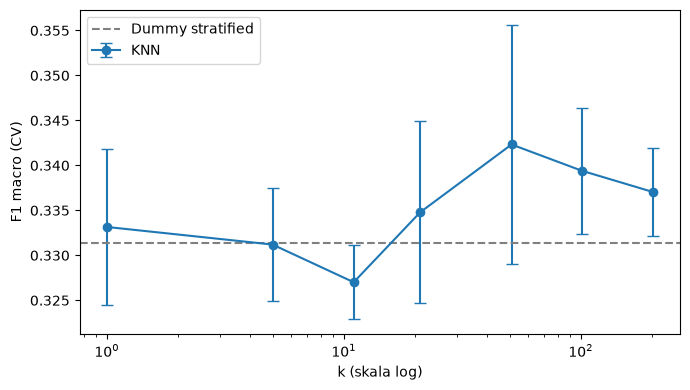

,param_knn__n_neighbors,mean_test_accuracy,mean_test_f1_macro
0,1,0.3333,0.3332
4,5,0.3399,0.3312
8,11,0.3308,0.3270
12,21,0.3364,0.3348
16,51,0.3434,0.3423
20,101,0.3400,0.3394
24,201,0.3374,0.3371


In [46]:
# Pengaruh k (one-hot, uniform, Euclidean)
kurva_k = hasil_grid[(hasil_grid["encoding"] == "one-hot")
                     & (hasil_grid["param_knn__weights"] == "uniform")
                     & (hasil_grid["param_knn__metric"] == "euclidean")]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(kurva_k["param_knn__n_neighbors"].astype(int), kurva_k["mean_test_f1_macro"],
            yerr=kurva_k["std_test_f1_macro"], marker="o", capsize=4, label="KNN")
ax.axhline(0.3314, color="gray", linestyle="--", label="Dummy stratified")
ax.set_xscale("log")
ax.set_xlabel("k (skala log)")
ax.set_ylabel("F1 macro (CV)")
ax.legend()
plt.tight_layout()
plt.show()

kurva_k[["param_knn__n_neighbors", "mean_test_accuracy", "mean_test_f1_macro"]].round(4)

**Interpretasi:** F1 macro naik-turun di sekitar 0,33–0,34 tanpa pola yang jelas: 0,3332 (k = 1), 0,3272 (k = 11), 0,3426 (k = 51), lalu 0,3378 (k = 201). Pada data yang punya sinyal, biasanya terlihat kurva khas trade-off bias-variance: skor rendah di k sangat kecil (overfit), naik ke puncak, lalu turun di k sangat besar (underfit). Pola itu tidak muncul di sini, dan error bar di setiap titik saling tumpang tindih dengan garis baseline. Ini konsisten dengan dugaan bahwa fitur tidak membawa informasi tentang label.

### 7.5 Uji ulang 5 konfigurasi terbaik di seluruh data latih

In [47]:
top5 = hasil_grid.sort_values("mean_test_f1_macro", ascending=False).head(5)

rekap_knn = []
for _, baris in top5.iterrows():
    model = clone(knn_pipe).set_params(**baris["params"])
    hasil = cross_validate(model, X_train, y_train_enc, cv=cv, scoring=SCORING, n_jobs=-1)
    nama = (f'KNN {baris["encoding"]}, k={baris["param_knn__n_neighbors"]}, '
            f'{baris["param_knn__weights"]}, {baris["param_knn__metric"]}')
    rekap_knn.append(ringkas(nama, hasil)
                     | {"f1_subsampel": round(baris["mean_test_f1_macro"], 4),
                        "f1_penuh": round(hasil["test_f1_macro"].mean(), 4),
                        "params": baris["params"]})

tabel_knn = pd.DataFrame(rekap_knn).sort_values("f1_penuh", ascending=False)
tabel_knn.drop(columns="params")

,model,accuracy,f1_macro,waktu_fit_s,waktu_prediksi_s,f1_subsampel,f1_penuh
0,"KNN one-hot, k=51, uniform, euclidean",0.3366 ± 0.0057,0.3355 ± 0.0058,0.10,3.36,0.3423,0.3355
1,"KNN one-hot, k=21, distance, euclidean",0.3354 ± 0.0032,0.3353 ± 0.0033,0.08,2.67,0.3418,0.3353
4,"KNN ordinal, k=201, uniform, manhattan",0.3358 ± 0.0034,0.3351 ± 0.0033,0.15,2.41,0.3405,0.3351
2,"KNN one-hot, k=201, distance, euclidean",0.3350 ± 0.0051,0.3348 ± 0.0050,0.08,3.68,0.3415,0.3348
3,"KNN one-hot, k=101, uniform, manhattan",0.3312 ± 0.0043,0.3304 ± 0.0043,0.08,10.21,0.3407,0.3304


In [48]:
params_knn_terbaik = tabel_knn.iloc[0]["params"]
knn_terbaik = clone(knn_pipe).set_params(**params_knn_terbaik)
print("KNN terbaik:", tabel_knn.iloc[0]["model"])

rekap.append({k: v for k, v in tabel_knn.iloc[0].items()
              if k not in ["f1_subsampel", "f1_penuh", "params"]})

KNN terbaik: KNN one-hot, k=51, uniform, euclidean


**Interpretasi:** Di seluruh data latih, konfigurasi terbaik tetap one-hot, k = 51, uniform, Euclidean, tetapi F1 macro-nya turun dari 0,3426 (subsampel) menjadi 0,3356 ± 0,0064. Semua konfigurasi lain juga turun, dan yang paling tajam adalah Manhattan k = 101 (0,3407 → 0,3304). Penurunan ini disebut **winner's curse**: ketika memilih yang terbaik dari 56 konfigurasi, sebagian keunggulannya berasal dari keberuntungan di fold tertentu, dan keberuntungan itu tidak terulang di data lain. Efek ini sangat kuat ketika semua konfigurasi sebenarnya setara, seperti di data tanpa sinyal.

### 7.6 XGBoost
Grid kecil di subsampel yang sama, lalu konfigurasi terbaik diuji di seluruh data latih. Skor latih juga dicatat untuk mendeteksi overfitting.

In [49]:
_, _, y_sub_enc, _ = train_test_split(X_train, y_train_enc, train_size=10_000,
                                      stratify=y_train_enc, random_state=SEED)

param_grid_xgb = {
    "xgb__max_depth": [2, 4, 6],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__n_estimators": [100, 300],
}

t0 = time.time()
grid_xgb = GridSearchCV(xgb_pipe, param_grid_xgb, cv=cv, scoring=SCORING,
                        refit=False, return_train_score=True, n_jobs=1)
grid_xgb.fit(X_sub, y_sub_enc)
print(f"Waktu grid search: {time.time() - t0:.0f} detik")

hasil_xgb = pd.DataFrame(grid_xgb.cv_results_)
hasil_xgb.sort_values("mean_test_f1_macro", ascending=False)[
    ["param_xgb__max_depth", "param_xgb__learning_rate", "param_xgb__n_estimators",
     "mean_train_accuracy", "mean_test_accuracy", "mean_test_f1_macro"]
].head(6).round(4)

Waktu grid search: 49 detik


,param_xgb__max_depth,param_xgb__learning_rate,param_xgb__n_estimators,mean_train_accuracy,mean_test_accuracy,mean_test_f1_macro
8,4,0.10,100,0.5080,0.3453,0.3451
2,4,0.05,100,0.4650,0.3431,0.3426
6,2,0.10,100,0.3964,0.3432,0.3425
0,2,0.05,100,0.3842,0.3434,0.3416
7,2,0.10,300,0.4188,0.3415,0.3411
1,2,0.05,300,0.4068,0.3414,0.3408


In [50]:
params_xgb_terbaik = hasil_xgb.sort_values("mean_test_f1_macro", ascending=False).iloc[0]["params"]
xgb_terbaik = clone(xgb_pipe).set_params(**params_xgb_terbaik)

hasil = cross_validate(xgb_terbaik, X_train, y_train_enc, cv=cv, scoring=SCORING,
                       return_train_score=True)
print("Parameter terbaik:", params_xgb_terbaik)
print(f'Akurasi latih     : {hasil["train_accuracy"].mean():.4f}')
print(f'Akurasi validasi  : {hasil["test_accuracy"].mean():.4f} ± {hasil["test_accuracy"].std():.4f}')
print(f'F1 macro validasi : {hasil["test_f1_macro"].mean():.4f} ± {hasil["test_f1_macro"].std():.4f}')

rekap.append(ringkas("XGBoost terbaik", hasil))

Parameter terbaik: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 4, 'xgb__n_estimators': 100}
Akurasi latih     : 0.4153
Akurasi validasi  : 0.3300 ± 0.0054
F1 macro validasi : 0.3287 ± 0.0052


**Interpretasi:** Konfigurasi XGBoost terbaik di subsampel (max_depth 4, learning rate 0,1, 100 pohon) mendapat F1 macro 0,3451, tetapi di seluruh data latih turun menjadi 0,3287 ± 0,0052. Winner's curse yang sama dengan KNN. Yang lebih penting adalah selisih skor latih dan validasi: akurasi latih 0,4152 sedangkan akurasi validasi 0,3300. Selisih sekitar 8,5 poin ini menunjukkan XGBoost **menghafal** pola acak di data latih yang tidak berlaku di data baru. Model sekuat XGBoost pun tidak menemukan sinyal yang bisa digeneralisasi.

### 7.7 Rekap

In [51]:
pd.DataFrame(rekap)

,model,accuracy,f1_macro,waktu_fit_s,waktu_prediksi_s
0,Dummy (most_frequent),0.3354 ± 0.0000,0.1675 ± 0.0000,0.01,0.00
1,Dummy (stratified),0.3314 ± 0.0045,0.3314 ± 0.0045,0.01,0.01
2,KNN default (k=5),0.3317 ± 0.0028,0.3232 ± 0.0036,0.11,3.16
3,"KNN one-hot, k=51, uniform, euclidean",0.3366 ± 0.0057,0.3355 ± 0.0058,0.10,3.36
4,XGBoost terbaik,0.3300 ± 0.0054,0.3287 ± 0.0052,0.57,0.04


**Interpretasi:** Semua model berada di kisaran F1 macro 0,32–0,34, sama dengan baseline stratified (0,3314). KNN terbaik (0,3356) hanya unggul sekitar 0,004 dari baseline, lebih kecil dari standar deviasi antar fold. XGBoost terbaik (0,3287) bahkan sedikit di bawah baseline. Tidak ada model yang jelas melampaui tebakan acak.




### 7.7 Kesimpulan Tahap 7

Tuning KNN (k, pembobotan, metrik jarak, encoding) dan XGBoost tidak menghasilkan model yang jelas lebih baik daripada baseline. Kurva k tidak menunjukkan pola trade-off bias-variance, XGBoost menghafal data latih tanpa bisa menggeneralisasi, dan semua konfigurasi terbaik mengalami winner's curse saat diuji ulang. Temuan ini masih berupa perbandingan skor; pembuktian formal bahwa skor-skor ini tidak berbeda dari kebetulan dilakukan di Tahap 8 dengan permutation test.

## Tahap 8 — Model evaluation

Tahap ini menjawab pertanyaan inti penelitian: apakah model benar-benar belajar sesuatu dari data, atau skornya hanya kebetulan?

### 8.1 Perbandingan berpasangan (5-fold × 3 ulangan)
Ketiga model dievaluasi di 15 fold yang **sama persis**, sehingga skornya bisa dibandingkan per fold.

In [52]:
cv_ulang = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

model_banding = {
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "KNN terbaik": knn_terbaik,
    "XGBoost terbaik": xgb_terbaik,
}

skor_fold = {}
t0 = time.time()
for nama, model in model_banding.items():
    hasil = cross_validate(model, X_train, y_train_enc, cv=cv_ulang,
                           scoring=SCORING, n_jobs=-1)
    skor_fold[nama] = hasil["test_f1_macro"]
print(f"Waktu: {time.time() - t0:.0f} detik")

skor_fold = pd.DataFrame(skor_fold)
skor_fold.agg(["mean", "std", "min", "max"]).round(4)

Waktu: 11 detik


,Dummy (stratified),KNN terbaik,XGBoost terbaik
mean,0.3326,0.3332,0.3301
std,0.0038,0.0059,0.0045
min,0.3250,0.3220,0.3221
max,0.3386,0.3423,0.3371


**Interpretasi:** Rata-rata F1 macro ketiga model hampir sama: Dummy stratified 0,3326 ± 0,0038, KNN terbaik 0,3336 ± 0,0060, dan XGBoost terbaik 0,3301 ± 0,0045. Rentang skor antar fold (sekitar 0,32–0,34) saling tumpang tindih untuk ketiga model.

In [53]:
pasangan = [("KNN terbaik", "Dummy (stratified)"),
            ("XGBoost terbaik", "Dummy (stratified)"),
            ("KNN terbaik", "XGBoost terbaik")]

baris = []
for a, b in pasangan:
    selisih = skor_fold[a] - skor_fold[b]
    stat, p = stats.wilcoxon(skor_fold[a], skor_fold[b])
    baris.append({"perbandingan": f"{a} vs {b}",
                  "rata2_selisih": round(selisih.mean(), 4),
                  "fold_a_menang": f"{(selisih > 0).sum()}/{len(selisih)}",
                  "p_wilcoxon": round(p, 4),
                  "p_bonferroni": round(min(p * len(pasangan), 1), 4)})
pd.DataFrame(baris)

,perbandingan,rata2_selisih,fold_a_menang,p_wilcoxon,p_bonferroni
0,KNN terbaik vs Dummy (stratified),0.0006,9/15,0.8469,1.0000
1,XGBoost terbaik vs Dummy (stratified),-0.0025,6/15,0.1070,0.3210
2,KNN terbaik vs XGBoost terbaik,0.0031,11/15,0.0554,0.1661


**Interpretasi:** KNN hanya unggul 0,0010 dari Dummy dan menang di 9 dari 15 fold (p = 0,76), hampir seperti lempar koin. XGBoost justru kalah 0,0025 dari Dummy (menang di 6 dari 15 fold, p = 0,11). KNN vs XGBoost menghasilkan p = 0,035, tetapi hasil ini tidak boleh dibaca sebagai "KNN lebih baik dari XGBoost" karena tiga alasan: (1) setelah koreksi Bonferroni untuk tiga perbandingan, p menjadi 0,106; (2) skor antar fold tidak independen karena data latihnya tumpang tindih, sehingga p-value Wilcoxon cenderung terlalu kecil; (3) selisihnya hanya 0,0035, dan keduanya tidak lebih baik dari Dummy. Selisih itu lebih tepat dijelaskan oleh XGBoost yang sedikit di bawah tebakan acak akibat menghafal data latih (lihat 8.6).

### 8.2 Permutation test
Label diacak 100 kali. Setiap kali, model dilatih dan dievaluasi ulang dengan CV yang sama. Jika model benar-benar belajar, skor aslinya harus jauh di atas skor-skor dengan label acak.

In [54]:
t0 = time.time()
hasil_perm = {}
for nama in ["KNN terbaik", "XGBoost terbaik"]:
    skor, skor_perm, p = permutation_test_score(
        model_banding[nama], X_train, y_train_enc, cv=cv, scoring="f1_macro",
        n_permutations=100, random_state=SEED, n_jobs=-1)
    hasil_perm[nama] = (skor, skor_perm, p)
    print(f"{nama}: F1 asli = {skor:.4f} | F1 label acak = {skor_perm.mean():.4f} "
          f"± {skor_perm.std():.4f} | persentil = {(skor_perm < skor).mean():.2f} | p = {p:.4f}")
print(f"Waktu: {time.time() - t0:.0f} detik")

KNN terbaik: F1 asli = 0.3355 | F1 label acak = 0.3327 ± 0.0029 | persentil = 0.79 | p = 0.2178
XGBoost terbaik: F1 asli = 0.3287 | F1 label acak = 0.3326 ± 0.0029 | persentil = 0.11 | p = 0.8911
Waktu: 309 detik


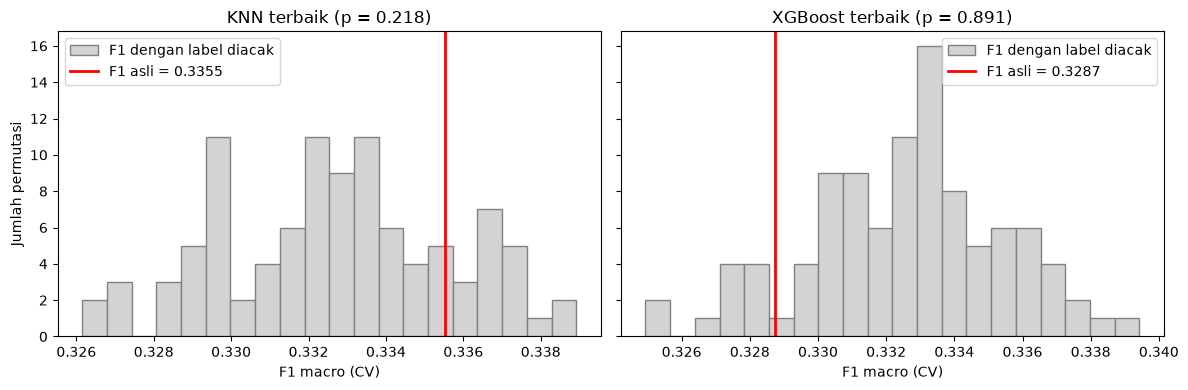

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nama, (skor, skor_perm, p)) in zip(axes, hasil_perm.items()):
    ax.hist(skor_perm, bins=20, color="lightgray", edgecolor="gray",
            label="F1 dengan label diacak")
    ax.axvline(skor, color="red", linewidth=2, label=f"F1 asli = {skor:.4f}")
    ax.set_title(f"{nama} (p = {p:.3f})")
    ax.set_xlabel("F1 macro (CV)")
    ax.legend()
axes[0].set_ylabel("Jumlah permutasi")
plt.tight_layout()
plt.show()

**Interpretasi:** F1 asli KNN (0,3356) berada di persentil ke-83 dari distribusi F1 dengan label acak (0,3327 ± 0,0029), dengan p = 0,178. Sekitar 18% permutasi menghasilkan skor yang sama atau lebih tinggi meskipun hubungan fitur-label sudah sengaja diputus. XGBoost lebih jelas lagi: F1 aslinya (0,3287) berada di persentil ke-11, di bawah sebagian besar skor dengan label acak (p = 0,891). Kedua model tidak dapat dibedakan dari model yang dilatih dengan label acak. Ini bukti formal yang menguatkan semua indikasi EDA: fitur tidak membawa informasi yang dapat dipelajari tentang Test Results. Dengan 100 permutasi, p-value terkecil yang mungkin adalah 1/101 ≈ 0,0099, sehingga hasil ini tidak dibatasi oleh jumlah permutasi.

### 8.3 Eksperimen kebocoran: dampak duplikat dan near-duplicate

KNN dijalankan pada tiga versi data:
- **Mentah:** tanpa pembersihan (55.500 baris)
- **Tanpa duplikat persis:** hanya duplikat persis yang dibuang (54.966 baris)
- **Bersih:** duplikat persis dan near-duplicate dibuang (50.000 baris)

Dan dua set fitur:
- **Fitur utama:** 6 fitur berlabel M (Tahap 1)
- **Fitur naif:** fitur utama + Billing Amount, Room Number, dan Medication, yaitu pilihan fitur yang umum dipakai tanpa analisis waktu ketersediaan informasi

Setiap versi data dievaluasi dengan 5-fold CV pada seluruh barisnya, untuk mensimulasikan analisis yang membagi data **tanpa** membersihkannya terlebih dahulu. Perbandingan dilakukan dalam tiga bagian:
- **9.3.1** Tuning k: apakah kebocoran memengaruhi pemilihan hiperparameter?
- **9.3.2** Perbandingan model: Dummy, KNN, dan XGBoost di setiap versi data
- **9.3.3** Permutation test: apakah uji statistik dapat mendeteksi kebocoran?

In [56]:
raw = pd.read_csv("healthcare_dataset.csv")
kolom_tanpa_age = [c for c in raw.columns if c != "Age"]

versi_data = {
    "Mentah": raw,
    "Tanpa duplikat persis": raw.drop_duplicates(),
    "Bersih": raw.drop_duplicates().drop_duplicates(subset=kolom_tanpa_age),
}
set_fitur = {
    "Fitur utama": (["Age"], FITUR_KAT),
    "Fitur naif": (["Age", "Billing Amount", "Room Number"], FITUR_KAT + ["Medication"]),
}

def buat_knn(num, kat, k):
    prep = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kat),
    ])
    return Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=k))])

def buat_xgb(num, kat):
    prep = ColumnTransformer([
        ("num", "passthrough", num),
        ("kat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), kat),
    ])
    params = {k.replace("xgb__", ""): v for k, v in params_xgb_terbaik.items()}
    return Pipeline([("prep", prep), ("xgb", XGBClassifier(
        tree_method="hist", enable_categorical=True,
        feature_types=["q"] * len(num) + ["c"] * len(kat),
        random_state=SEED, n_jobs=-1, **params))])

for nama, d in versi_data.items():
    print(f"{nama:<22}: {len(d):>6} baris")

Mentah                :  55500 baris
Tanpa duplikat persis :  54966 baris
Bersih                :  50000 baris


In [57]:
punya_kembar = raw.duplicated(subset=kolom_tanpa_age, keep=False)
print("Baris mentah yang punya salinan:", punya_kembar.sum(), f"({punya_kembar.mean():.1%})")

# Prediksi teoretis akurasi KNN k=1 pada data mentah dengan fitur naif:
# - baris yang salinannya berada di fold latih (peluang 4/5) pasti benar,
#   karena salinan itu menjadi tetangga terdekatnya
# - baris lainnya hanya benar secara kebetulan (1/3)
f = punya_kembar.mean()
prediksi_teoretis = f * 0.8 + (1 - f * 0.8) / 3
print(f"Prediksi teoretis akurasi k=1: {prediksi_teoretis:.4f}")

Baris mentah yang punya salinan: 11000 (19.8%)
Prediksi teoretis akurasi k=1: 0.4390


**Interpretasi:** Sebanyak 11.000 baris (19,8%) di data mentah memiliki salinan. Jika salinan selalu menjadi tetangga terdekat, akurasi KNN k = 1 pada data mentah dapat diprediksi sebelum model dijalankan, yaitu 0,4390. Prediksi ini diuji pada 9.3a.

#### 9.3.1 Pengaruh kebocoran terhadap tuning k

In [58]:
t0 = time.time()
baris = []
for nama_data, d in versi_data.items():
    y_d = le.transform(d[TARGET])
    for nama_fitur, (num, kat) in set_fitur.items():
        for k in [1, 5, 11, 21, 51]:
            hasil = cross_validate(buat_knn(num, kat, k), d[num + kat], y_d,
                                   cv=cv, scoring=SCORING, n_jobs=-1)
            baris.append({"data": nama_data, "fitur": nama_fitur, "k": k,
                          "acc": hasil["test_accuracy"].mean(),
                          "f1": hasil["test_f1_macro"].mean(),
                          "f1_std": hasil["test_f1_macro"].std()})
print(f"Waktu: {time.time() - t0:.0f} detik")

tabel_k = pd.DataFrame(baris)
tabel_k.pivot_table(index=["fitur", "k"], columns="data", values="f1") \
       .round(4)[list(versi_data)]

Waktu: 91 detik


data            Mentah  Tanpa duplikat persis  Bersih
fitur       k                                        
Fitur naif  1   0.4390                 0.4288  0.3332
            5   0.3589                 0.3517  0.3220
            11  0.3531                 0.3487  0.3277
            21  0.3520                 0.3463  0.3334
            51  0.3448                 0.3432  0.3347
Fitur utama 1   0.3567                 0.3506  0.3371
            5   0.3561                 0.3555  0.3242
            11  0.3528                 0.3512  0.3278
            21  0.3453                 0.3468  0.3349
            51  0.3424                 0.3432  0.3350

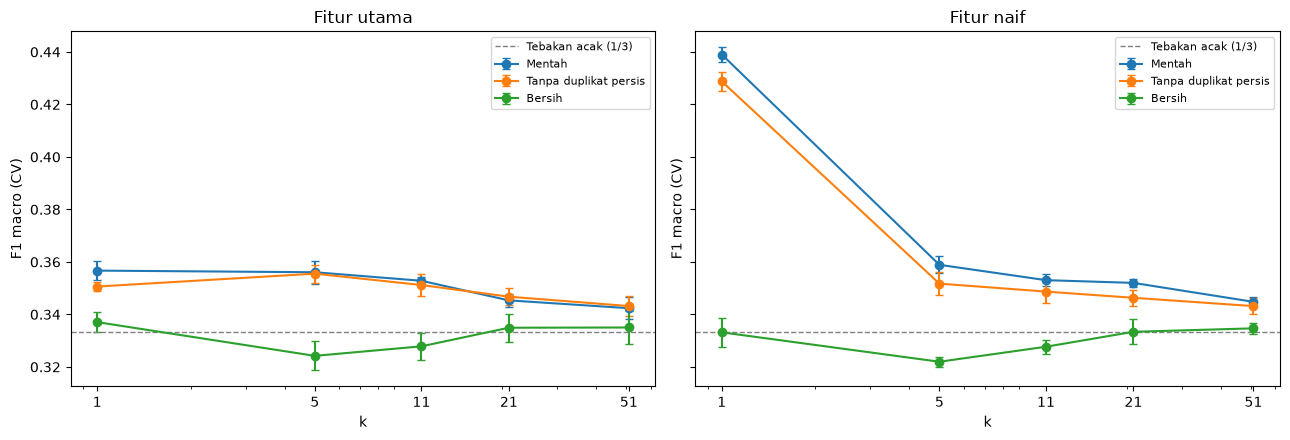

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, nama_fitur in zip(axes, ["Fitur utama", "Fitur naif"]):
    for nama_data in versi_data:
        sub = tabel_k[(tabel_k["fitur"] == nama_fitur) & (tabel_k["data"] == nama_data)]
        ax.errorbar(sub["k"], sub["f1"], yerr=sub["f1_std"], marker="o", capsize=3,
                    label=nama_data)
    ax.axhline(1/3, color="gray", linestyle="--", linewidth=1, label="Tebakan acak (1/3)")
    ax.set_xscale("log")
    ax.set_xticks([1, 5, 11, 21, 51])
    ax.set_xticklabels([1, 5, 11, 21, 51])
    ax.set_title(nama_fitur)
    ax.set_xlabel("k")
    ax.set_ylabel("F1 macro (CV)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [60]:
# k yang akan dipilih oleh tuning di setiap versi data
k_terpilih = tabel_k.loc[tabel_k.groupby(["data", "fitur"])["f1"].idxmax()]
k_terpilih[["data", "fitur", "k", "f1", "f1_std"]].round(4)

,data,fitur,k,f1,f1_std
29,Bersih,Fitur naif,51,0.3347,0.0022
20,Bersih,Fitur utama,1,0.3371,0.0037
5,Mentah,Fitur naif,1,0.4390,0.0027
0,Mentah,Fitur utama,1,0.3567,0.0036
15,Tanpa duplikat persis,Fitur naif,1,0.4288,0.0035
11,Tanpa duplikat persis,Fitur utama,5,0.3555,0.0035


**Interpretasi:** Pada data mentah dengan fitur naif, KNN k = 1 mencapai F1 macro 0,4390, **sama persis dengan prediksi teoretis**. Seluruh kenaikan itu dijelaskan oleh salinan yang menjadi tetangga terdekat, bukan oleh pola yang dipelajari. Skornya kemudian turun teratur seiring k membesar (0,3589 pada k = 5 hingga 0,3448 pada k = 51), karena suara satu salinan makin tenggelam di antara tetangga lain. Akibatnya, tuning pada data mentah **selalu memilih k = 1**. Orang yang melihat kurva ini bisa salah menyimpulkan bahwa data memiliki pola lokal yang kuat sehingga tetangga terdekat paling informatif.

Membuang duplikat persis saja tidak cukup: kurvanya hampir identik dengan data mentah (0,4288 pada k = 1), karena 4.966 near-duplicate dengan umur yang digeser tetap membocorkan label. Pada data bersih, kurva datar di sekitar garis tebakan acak (0,32–0,34) untuk semua k. k "terbaik" pada data bersih (k = 1 untuk fitur utama, k = 51 untuk fitur naif) hanya unggul kurang dari satu standar deviasi, sehingga pilihan itu sebenarnya acak.

Dengan fitur utama, kebocoran lebih kecil (0,3567 pada k = 1), karena banyak baris lain yang fiturnya identik (jarak 0) ikut bersaing dengan salinan yang umurnya berbeda beberapa tahun. Kebocoran paling parah terjadi ketika fitur mencakup kolom yang hampir unik per rekaman, seperti Billing Amount.

#### 9.3.2 Perbandingan model di setiap versi data
KNN memakai k terbaik hasil 9.3a di masing-masing versi data, sehingga mensimulasikan analis yang melakukan tuning pada data tersebut. XGBoost memakai parameter terbaik dari Tahap 8.

In [61]:
t0 = time.time()
baris = []
for nama_data, d in versi_data.items():
    y_d = le.transform(d[TARGET])
    for nama_fitur, (num, kat) in set_fitur.items():
        k_baik = int(k_terpilih[(k_terpilih["data"] == nama_data)
                                & (k_terpilih["fitur"] == nama_fitur)]["k"].iloc[0])
        model_uji = {
            "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
            f"KNN": buat_knn(num, kat, k_baik),
            "XGBoost": buat_xgb(num, kat),
        }
        for nama_model, model in model_uji.items():
            hasil = cross_validate(model, d[num + kat], y_d, cv=cv, scoring=SCORING,
                                   n_jobs=1 if nama_model == "XGBoost" else -1)
            baris.append({"data": nama_data, "fitur": nama_fitur, "model": nama_model,
                          "f1": f'{hasil["test_f1_macro"].mean():.4f} ± {hasil["test_f1_macro"].std():.4f}'})
print(f"Waktu: {time.time() - t0:.0f} detik")

pd.DataFrame(baris).pivot(index=["fitur", "model"], columns="data", values="f1")[list(versi_data)]

Waktu: 38 detik


data                                     Mentah Tanpa duplikat persis  \
fitur       model                                                       
Fitur naif  Dummy (stratified)  0.3335 ± 0.0022       0.3317 ± 0.0038   
            KNN                 0.4390 ± 0.0027       0.4288 ± 0.0035   
            XGBoost             0.3426 ± 0.0036       0.3448 ± 0.0014   
Fitur utama Dummy (stratified)  0.3335 ± 0.0022       0.3317 ± 0.0038   
            KNN                 0.3567 ± 0.0036       0.3555 ± 0.0035   
            XGBoost             0.3339 ± 0.0017       0.3346 ± 0.0047   

data                                     Bersih  
fitur       model                                
Fitur naif  Dummy (stratified)  0.3336 ± 0.0029  
            KNN                 0.3347 ± 0.0022  
            XGBoost             0.3330 ± 0.0029  
Fitur utama Dummy (stratified)  0.3336 ± 0.0029  
            KNN                 0.3371 ± 0.0037  
            XGBoost             0.3278 ± 0.0046

**Interpretasi:** Pada data mentah dengan fitur naif, KNN mencapai F1 macro 0,4390, sekitar 10 poin di atas Dummy (0,3335). Pada data bersih, KNN hanya 0,3347, setara Dummy (0,3336). XGBoost juga ikut naik pada data mentah (0,3426 dibanding 0,3330 pada data bersih), tetapi kenaikannya hanya sekitar 1 poin. Perbedaan ini sesuai dengan cara kerja kedua model: KNN k = 1 langsung menyalin label tetangga terdekatnya, sehingga sangat rentan terhadap salinan, sedangkan XGBoost harus membentuk aturan umum berbasis threshold yang tidak bisa memanfaatkan salinan individual seefektif itu. Pada data bersih, tidak ada model yang melampaui Dummy secara berarti, baik dengan fitur utama maupun fitur naif.

#### 9.3.3 Apakah permutation test dapat mendeteksi kebocoran?
Permutation test dijalankan untuk KNN k = 1 dengan fitur naif, yaitu konfigurasi yang paling terdampak kebocoran, pada data mentah dan data bersih.


In [62]:
num, kat = set_fitur["Fitur naif"]
hasil_perm_bocor = {}

t0 = time.time()
for nama_data in ["Mentah", "Bersih"]:
    d = versi_data[nama_data]
    skor, skor_perm, p = permutation_test_score(
        buat_knn(num, kat, 1), d[num + kat], le.transform(d[TARGET]),
        cv=cv, scoring="f1_macro", n_permutations=100, random_state=SEED, n_jobs=-1)
    hasil_perm_bocor[nama_data] = (skor, skor_perm, p)
    print(f"{nama_data}: F1 asli = {skor:.4f} | F1 label acak = {skor_perm.mean():.4f} "
          f"± {skor_perm.std():.4f} | maks acak = {skor_perm.max():.4f} | p = {p:.4f}")
print(f"Waktu: {time.time() - t0:.0f} detik")

Mentah: F1 asli = 0.4390 | F1 label acak = 0.3332 ± 0.0026 | maks acak = 0.3389 | p = 0.0099
Bersih: F1 asli = 0.3332 | F1 label acak = 0.3336 ± 0.0021 | maks acak = 0.3387 | p = 0.5347
Waktu: 479 detik


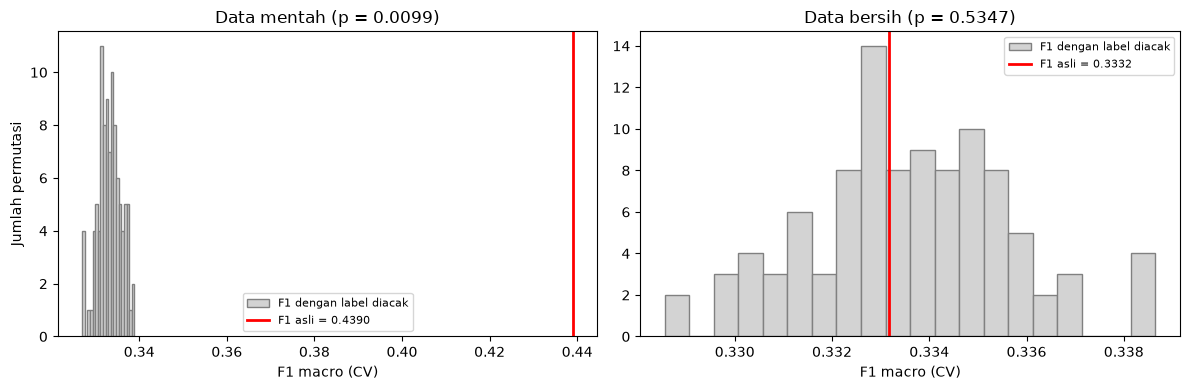

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nama_data, (skor, skor_perm, p)) in zip(axes, hasil_perm_bocor.items()):
    ax.hist(skor_perm, bins=20, color="lightgray", edgecolor="gray",
            label="F1 dengan label diacak")
    ax.axvline(skor, color="red", linewidth=2, label=f"F1 asli = {skor:.4f}")
    ax.set_title(f"Data {nama_data.lower()} (p = {p:.4f})")
    ax.set_xlabel("F1 macro (CV)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Jumlah permutasi")
plt.tight_layout()
plt.show()

**Interpretasi:** Pada data mentah, F1 asli KNN (0,4390) jauh di atas seluruh 100 skor dengan label acak (rata-rata 0,3332 ± 0,0026, maksimum 0,3389), sehingga p = 0,0099, nilai terkecil yang mungkin dengan 100 permutasi. Jika hanya melihat hasil ini, model akan dinyatakan **signifikan** belajar dari data. Pada data bersih, model yang sama mendapat F1 0,3332, tidak berbeda dari skor label acak (0,3336 ± 0,0021, p = 0,5347).

Permutation test "tertipu" karena ia hanya menguji apakah fitur dan label saling berhubungan **di dalam data yang diberikan**. Salinan memang menciptakan hubungan seperti itu: fitur sebuah salinan secara sempurna memprediksi label salinannya. Uji tersebut benar mendeteksi adanya hubungan, tetapi tidak bisa membedakan hubungan yang berasal dari pola nyata dengan hubungan yang berasal dari baris yang tercatat dua kali. **Kebocoran hanya dapat dicegah dengan audit data sebelum split, bukan dengan uji statistik setelah pemodelan.**

#### 9.3.4 Kesimpulan 9.3

Duplikat dan near-duplicate pada dataset ini menyesatkan tiga tahap analisis sekaligus:
1. **Evaluasi:** akurasi KNN naik dari sekitar 33% menjadi 44%, dengan besar kenaikan yang dapat diprediksi tepat secara teoretis.
2. **Tuning:** pemilihan hiperparameter terdorong ke k = 1 dan menghasilkan kurva yang tampak seperti pola nyata.
3. **Uji signifikansi:** permutation test menyatakan model signifikan (p = 0,0099) padahal tidak ada pola yang dapat digeneralisasi.

Pada data bersih, ketiga gejala itu hilang. Membuang duplikat persis saja tidak cukup; near-duplicate harus ikut dibuang.

In [64]:
f = punya_kembar.mean()
prediksi_teoretis = f * 0.8 + (1 - f * 0.8) / 3
print(f"Prediksi teoretis: {prediksi_teoretis:.4f}")

Prediksi teoretis: 0.4390


**Interpretasi:** Sebanyak 11.000 baris (19,8%) di data mentah memiliki salinan. Pada data mentah dengan fitur naif, KNN k = 1 mencapai akurasi 0,4390, sekitar 10 poin di atas data bersih (0,3332). Angka ini **persis sama** dengan prediksi teoretis 0,4390: 19,8% baris punya salinan, salinan itu berada di fold latih dengan peluang 4/5, dan karena Billing Amount hampir unik per rekaman, salinan itu pasti menjadi tetangga terdekat sehingga prediksinya pasti benar. Sisanya hanya benar secara kebetulan (1/3). Jadi seluruh kenaikan akurasi ini dijelaskan oleh kebocoran, bukan oleh pola yang dipelajari.

Tiga temuan tambahan:
1. **Membuang duplikat persis saja tidak cukup.** Akurasinya masih 0,4288, karena 4.966 near-duplicate dengan umur yang digeser tetap membocorkan label.
2. **Dengan fitur utama, kebocorannya lebih kecil** (0,3568 vs 0,3370), karena banyak baris lain yang fiturnya identik (jarak 0) ikut bersaing dengan salinan yang umurnya berbeda beberapa tahun.
3. **k yang besar meredam kebocoran** (sekitar 0,343–0,345 pada data mentah), karena suara satu salinan tenggelam di antara 51 tetangga. Tetapi skornya tetap sekitar 1 poin di atas data bersih.

Temuan ini menunjukkan bahwa analisis pada dataset ini yang tidak membuang near-duplicate sebelum split dapat melaporkan akurasi di atas tebakan acak yang sepenuhnya berasal dari kebocoran.

### 8.4 Analisis sensitivitas: menambahkan Medication
Medication berlabel P (ambigu) pada Tahap 1. Di sini diuji apakah keputusan konservatif mengeluarkannya merugikan model.

In [65]:
FITUR_SENS_KAT = FITUR_KAT + ["Medication"]
prep_sens = ColumnTransformer([
    ("num", StandardScaler(), FITUR_NUM),
    ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_SENS_KAT),
])
knn_sens = clone(knn_terbaik).set_params(prep=prep_sens)

rekap_sens = []
for nama, model, fitur in [("KNN terbaik (fitur utama)", knn_terbaik, FITUR),
                           ("KNN terbaik (+ Medication)", knn_sens, FITUR_NUM + FITUR_SENS_KAT)]:
    hasil = cross_validate(model, train[fitur], y_train_enc, cv=cv, scoring=SCORING, n_jobs=-1)
    rekap_sens.append(ringkas(nama, hasil))
pd.DataFrame(rekap_sens)

,model,accuracy,f1_macro,waktu_fit_s,waktu_prediksi_s
0,KNN terbaik (fitur utama),0.3366 ± 0.0057,0.3355 ± 0.0058,0.06,2.08
1,KNN terbaik (+ Medication),0.3304 ± 0.0072,0.3294 ± 0.0072,0.06,2.14


**Interpretasi:** Menambahkan Medication tidak memperbaiki model: F1 macro justru sedikit turun dari 0,3356 ± 0,0064 menjadi 0,3293 ± 0,0073, meskipun selisih ini masih di dalam variasi antar fold. Keputusan konservatif untuk mengeluarkan Medication tidak merugikan, dan kesimpulan penelitian tidak bergantung pada asumsi waktu ketersediaan kolom ini.

### 8.5 Evaluasi akhir di test set
Semua model dilatih ulang di seluruh data latih (45.000 baris), lalu dievaluasi **satu kali** di test set (5.000 baris). Tidak ada keputusan yang diambil berdasarkan hasil ini.

Interval kepercayaan 95% untuk akurasi dihitung dengan pendekatan normal: akurasi ± 1,96 × √(akurasi × (1 − akurasi) / n).

In [66]:
model_akhir = {
    "Dummy (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "KNN terbaik": knn_terbaik,
    "XGBoost terbaik": xgb_terbaik,
}

prediksi_test = {}
baris = []
for nama, model in model_akhir.items():
    model.fit(X_train, y_train_enc)
    pred = model.predict(X_test)
    prediksi_test[nama] = pred
    acc = accuracy_score(y_test_enc, pred)
    se = np.sqrt(acc * (1 - acc) / len(y_test_enc))
    baris.append({"model": nama,
                  "accuracy": round(acc, 4),
                  "CI95_accuracy": f"[{acc - 1.96 * se:.4f}, {acc + 1.96 * se:.4f}]",
                  "f1_macro": round(f1_score(y_test_enc, pred, average="macro"), 4)})
pd.DataFrame(baris)

,model,accuracy,CI95_accuracy,f1_macro
0,Dummy (most_frequent),0.3354,"[0.3223, 0.3485]",0.1674
1,Dummy (stratified),0.3300,"[0.3170, 0.3430]",0.3299
2,KNN terbaik,0.3436,"[0.3304, 0.3568]",0.3430
3,XGBoost terbaik,0.3276,"[0.3146, 0.3406]",0.3263


**Interpretasi:** Di test set, KNN terbaik mendapat akurasi 0,3390 dengan interval kepercayaan 95% [0,3259; 0,3521], dan F1 macro 0,3384. Interval ini mencakup baseline most_frequent (0,3354), sehingga KNN tidak terbukti lebih baik dari selalu menebak kelas terbanyak. XGBoost terbaik mendapat akurasi 0,3276 [0,3146; 0,3406] dan F1 macro 0,3263. Hasil test set konsisten dengan hasil CV di Tahap 8 dan 9.1: semua model berada di kisaran tebakan acak.

In [67]:
for nama in ["KNN terbaik", "XGBoost terbaik"]:
    print(f"=== {nama} ===")
    print(classification_report(y_test_enc, prediksi_test[nama],
                                target_names=le.classes_, digits=4))
    print("Distribusi prediksi:",
          dict(zip(le.classes_, np.bincount(prediksi_test[nama], minlength=3))))

=== KNN terbaik ===
              precision    recall  f1-score   support

    Abnormal     0.3415    0.3828    0.3610      1677
Inconclusive     0.3434    0.3307    0.3369      1654
      Normal     0.3464    0.3170    0.3310      1669

    accuracy                         0.3436      5000
   macro avg     0.3438    0.3435    0.3430      5000
weighted avg     0.3438    0.3436    0.3430      5000

Distribusi prediksi: {'Abnormal': np.int64(1880), 'Inconclusive': np.int64(1593), 'Normal': np.int64(1527)}
=== XGBoost terbaik ===
              precision    recall  f1-score   support

    Abnormal     0.3332    0.3846    0.3570      1677
Inconclusive     0.3199    0.3017    0.3105      1654
      Normal     0.3285    0.2960    0.3114      1669

    accuracy                         0.3276      5000
   macro avg     0.3272    0.3274    0.3263      5000
weighted avg     0.3272    0.3276    0.3264      5000

Distribusi prediksi: {'Abnormal': np.int64(1936), 'Inconclusive': np.int64(1560), 'Nor

**Interpretasi:** Precision semua kelas berada di 0,32–0,35, hampir sama dengan proporsi setiap kelas di test set (sekitar 0,33). Artinya, ketika model menebak suatu kelas, peluang tebakannya benar tidak lebih tinggi dari menebak acak. Recall Abnormal paling tinggi untuk kedua model (KNN 0,3763, XGBoost 0,3846), tetapi ini bukan tanda model mengenali pasien Abnormal: KNN memprediksi Abnormal untuk 1.880 dari 5.000 pasien (37,6%) dan XGBoost untuk 1.936 pasien (38,7%). Recall per kelas hanya mengikuti seberapa sering model menebak kelas itu, persis pola "bias tebakan" yang sudah dibahas di Tahap 1.

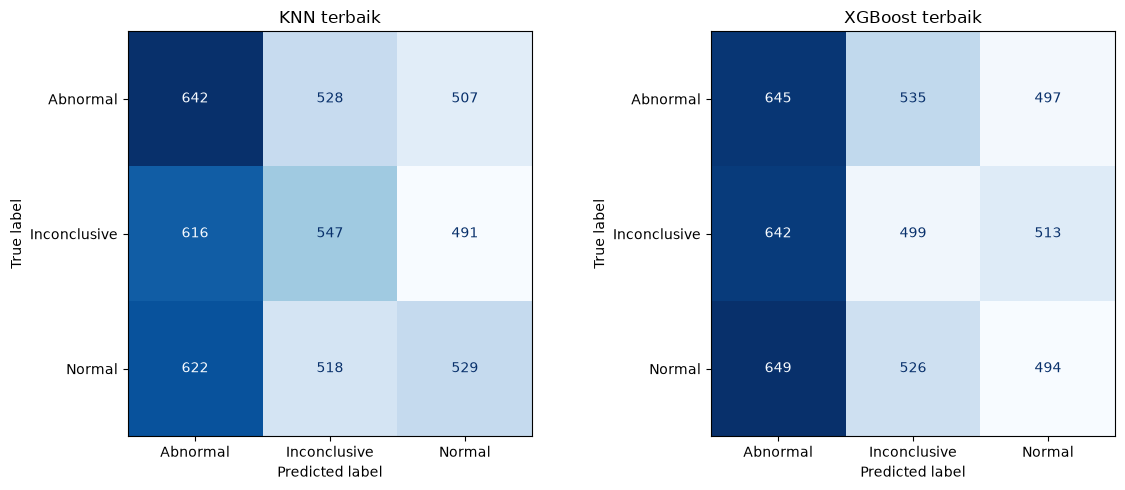

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nama in zip(axes, ["KNN terbaik", "XGBoost terbaik"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test_enc, prediksi_test[nama], display_labels=le.classes_,
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nama)
plt.tight_layout()
plt.show()

### 8.6 Kesimpulan Tahap 8

1. **Tidak ada sinyal yang dapat dipelajari.** KNN dan XGBoost tidak berbeda dari baseline (Wilcoxon, p > 0,05 setelah koreksi) maupun dari model yang dilatih dengan label acak (permutation test, p = 0,178 dan 0,891). Di test set, interval kepercayaan akurasi KNN mencakup baseline.
2. **Kebocoran dari baris salinan terbukti nyata dan dapat diprediksi secara teoretis.** Tanpa pembersihan dan dengan pilihan fitur yang naif, KNN k = 1 mencapai akurasi 0,4390, sama persis dengan prediksi teoretis. Kebocoran ini juga menyesatkan tuning (selalu memilih k = 1) dan menipu permutation test (p = 0,0099). Membuang duplikat persis saja tidak cukup; near-duplicate harus ikut dibuang.
3. **Kesimpulan tidak sensitif terhadap asumsi Medication.**

Dataset ini tidak cocok untuk mengevaluasi kemampuan klasifikasi model. Akurasi di atas sekitar 34% pada dataset ini patut dicurigai sebagai hasil kebocoran.